In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context("notebook")


In [3]:
adata = sc.read_h5ad(
    "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_DEEPDIVE_curated.h5ad",
    backed="r",
)
print(adata)

# ATTENTION: Filtering for cases
mask = (adata.obs["Status"] == "Case")
        #(adata.obs["CAGLENGTH"].notna() & 
       #(adata.obs["experiment"] == "deepdive") & 
    
adata = adata[mask].to_memory().copy()
print(adata)

adata.var_names = adata.var["gene_symbol"].astype(str)
adata.var_names_make_unique()

adata.obs["DONOR"].value_counts()


AnnData object with n_obs × n_vars = 329791 × 36943 backed at '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_DEEPDIVE_curated.h5ad'
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_pro

DONOR
S04002    44536
S07681    43630
S09619    38679
S06758    35895
S05202    32297
S12365    27270
S05368    24369
S02205    20059
Name: count, dtype: int64

# format cag elngth

In [4]:
germline = (
    adata.obs[["DONOR", "CAG"]]
    .drop_duplicates()
    .dropna()
    .assign(CAG=lambda d: d["CAG"].astype(str))
)

germline[["allele_a", "allele_b"]] = germline["CAG"].str.split("/", expand=True).astype(int)
germline["WT_germline"] = germline[["allele_a", "allele_b"]].min(axis=1)
germline["EXP_germline"] = germline[["allele_a", "allele_b"]].max(axis=1)
germline = germline.set_index("DONOR")[["WT_germline", "EXP_germline"]]

germline["Status"] = adata.obs.drop_duplicates("DONOR").set_index("DONOR").loc[germline.index, "Status"]

germline


,WT_germline,EXP_germline,Status
DONOR,,,
S02205,20,42,Case
S04002,17,42,Case
S05202,15,42,Case
S05368,16,39,Case
S06758,18,43,Case
S07681,16,42,Case
S09619,22,37,Case
S12365,17,40,Case


In [5]:
adata.obs = adata.obs.merge(germline[["WT_germline", "EXP_germline"]], left_on="DONOR", right_index=True)
adata.obs

,reaction,experiment,CELL_BARCODE,DONOR,SID,Age,Sex,Status,CAG,PMI,...,log1p_total_counts_mt,pct_counts_mt,leiden_0.1_all_cells,leiden_0.5_all_cells,leiden_0.07_all_cells,broad_ct,ct_for_deg,is_neuron,WT_germline,EXP_germline
S02205_Caudate_DeepDive_rxn1_TCCTAATTCCACGGAC,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_TCCTAATTCCACGGAC,S02205,S02205,48,Female,Case,20/42,30.80,...,5.347108,0.120387,0,0,0,MSN,Matrix_D2,True,20,42
S02205_Caudate_DeepDive_rxn1_CCCTCTCTCGATTCCC,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_CCCTCTCTCGATTCCC,S02205,S02205,48,Female,Case,20/42,30.80,...,4.430817,0.051398,1,2,1,MSN,Matrix_D1,True,20,42
S02205_Caudate_DeepDive_rxn1_ATATCCTGTATGAGGC,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_ATATCCTGTATGAGGC,S02205,S02205,48,Female,Case,20/42,30.80,...,4.430817,0.054072,1,2,1,MSN,Matrix_D1,True,20,42
S02205_Caudate_DeepDive_rxn1_GAGACCCAGCCATATC,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_GAGACCCAGCCATATC,S02205,S02205,48,Female,Case,20/42,30.80,...,2.639057,0.008724,1,2,1,MSN,Patch_D1,True,20,42
S02205_Caudate_DeepDive_rxn1_AGAGAATTCCGCGATG,S02205_Caudate_DeepDive_rxn1,deepdive,S02205_Caudate_DeepDive_rxn1_AGAGAATTCCGCGATG,S02205,S02205,48,Female,Case,20/42,30.80,...,4.744932,0.082265,1,2,1,MSN,Matrix_D1,True,20,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S12365_Caudate_DeepDive_rxn4_GTGATGTAGTATTAGG,S12365_Caudate_DeepDive_rxn4,deepdive,S12365_Caudate_DeepDive_rxn4_GTGATGTAGTATTAGG,S12365,S12365,81,Female,Case,17/40,17.33,...,1.791759,0.172771,8,12,7,Oligo,Oligodendrocyte,False,17,40
S12365_Caudate_DeepDive_rxn4_AGGATAAAGAATCCCT,S12365_Caudate_DeepDive_rxn4,deepdive,S12365_Caudate_DeepDive_rxn4_AGGATAAAGAATCCCT,S12365,S12365,81,Female,Case,17/40,17.33,...,2.397895,0.346380,8,13,7,Oligo,Oligodendrocyte,False,17,40
S12365_Caudate_DeepDive_rxn4_AGCGTATGTCGTGATT,S12365_Caudate_DeepDive_rxn4,deepdive,S12365_Caudate_DeepDive_rxn4_AGCGTATGTCGTGATT,S12365,S12365,81,Female,Case,17/40,17.33,...,1.386294,0.122050,8,13,7,Oligo,Oligodendrocyte,False,17,40
S12365_Caudate_DeepDive_rxn4_CAATACGCAGAGTGTG,S12365_Caudate_DeepDive_rxn4,deepdive,S12365_Caudate_DeepDive_rxn4_CAATACGCAGAGTGTG,S12365,S12365,81,Female,Case,17/40,17.33,...,2.197225,0.342173,8,13,7,Oligo,Oligodendrocyte,False,17,40


In [15]:
# trnafporm into expanstion
adata.obs["expansion"] = adata.obs["CAGLENGTH"] - adata.obs["EXP_germline"]

# Subset ot MSN

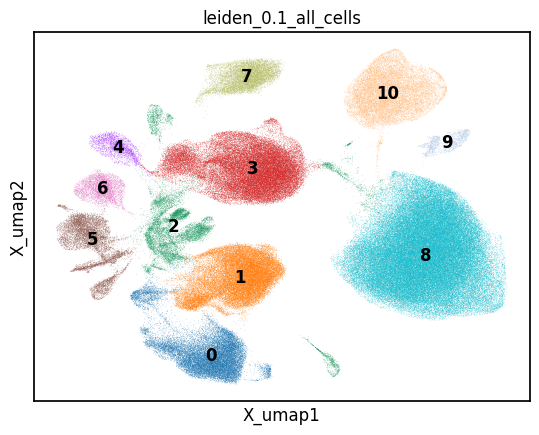

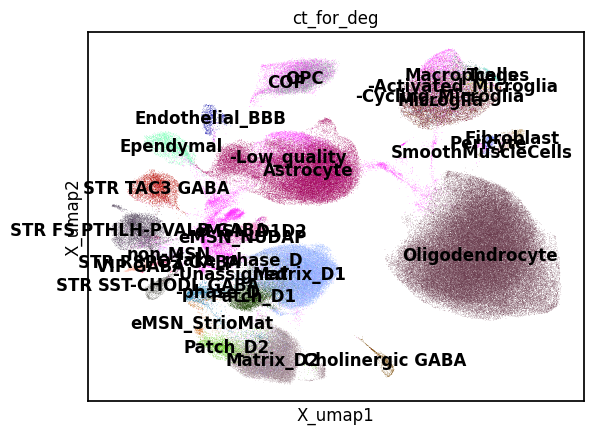

AnnData object with n_obs × n_vars = 266735 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zon

In [6]:
adata

sc.pl.embedding(adata, basis="X_umap", color="leiden_0.1_all_cells", legend_loc="on data")
sc.pl.embedding(adata, basis="X_umap", color="ct_for_deg", legend_loc="on data")


adata

In [ ]:
from utils import label_mapping_utils as lmu


adata_msn = adata[
                adata.obs["leiden_0.1_all_cells"].isin(["0", "1"]) &
                ~ adata.obs["ct_for_deg"].isin(["-Unassigned", "-fake_phase_D", "-Low_quality", "eMSN_StrioMat"])
                ].copy()


leiden_cluster_names = lmu.preprocess_common_pipeline(adata_msn, leiden_name="_all_cells", integrate_with_harmony=True, batch_key="DONOR", 
                                                      resolutions=[0.1, 0.5, 1.0, 1.5])

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


Running Harmony...
Running PCA before Harmony...


2026-11-01 20:02:39,711 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-11-01 20:02:39 | [INFO] Running Harmony (PyTorch on cuda)
2026-11-01 20:02:39,712 - harmonypy - INFO -   Parameters:
2026-11-01 20:02:39 | [INFO]   Parameters:
2026-11-01 20:02:39,713 - harmonypy - INFO -     max_iter_harmony: 30
2026-11-01 20:02:39 | [INFO]     max_iter_harmony: 30
2026-11-01 20:02:39,714 - harmonypy - INFO -     max_iter_kmeans: 20
2026-11-01 20:02:39 | [INFO]     max_iter_kmeans: 20
2026-11-01 20:02:39,716 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-11-01 20:02:39 | [INFO]     epsilon_cluster: 1e-05
2026-11-01 20:02:39,717 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-11-01 20:02:39 | [INFO]     epsilon_harmony: 0.0001
2026-11-01 20:02:39,718 - harmonypy - INFO -     nclust: 100
2026-11-01 20:02:39 | [INFO]     nclust: 100
2026-11-01 20:02:39,718 - harmonypy - INFO -     block_size: 0.05
2026-11-01 20:02:39 | [INFO]     block_size: 0.05
2026-11-01 20:02:39,720 - harm

Running Harmony batch correction...


2026-11-01 20:02:40,835 - harmonypy - INFO - KMeans initialization complete.
2026-11-01 20:02:40 | [INFO] KMeans initialization complete.
2026-11-01 20:02:40,842 - harmonypy - INFO - Iteration 1 of 30
2026-11-01 20:02:40 | [INFO] Iteration 1 of 30
2026-11-01 20:02:41,322 - harmonypy - INFO - Iteration 2 of 30
2026-11-01 20:02:41 | [INFO] Iteration 2 of 30
2026-11-01 20:02:41,760 - harmonypy - INFO - Iteration 3 of 30
2026-11-01 20:02:41 | [INFO] Iteration 3 of 30
2026-11-01 20:02:42,222 - harmonypy - INFO - Iteration 4 of 30
2026-11-01 20:02:42 | [INFO] Iteration 4 of 30
2026-11-01 20:02:42,667 - harmonypy - INFO - Iteration 5 of 30
2026-11-01 20:02:42 | [INFO] Iteration 5 of 30
2026-11-01 20:02:43,023 - harmonypy - INFO - Iteration 6 of 30
2026-11-01 20:02:43 | [INFO] Iteration 6 of 30
2026-11-01 20:02:43,334 - harmonypy - INFO - Iteration 7 of 30
2026-11-01 20:02:43 | [INFO] Iteration 7 of 30
2026-11-01 20:02:43,597 - harmonypy - INFO - Iteration 8 of 30
2026-11-01 20:02:43 | [INFO] 

Z_corr shape: (54934, 50), n_obs: 54934
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


<Axes: ylabel='Frequency'>

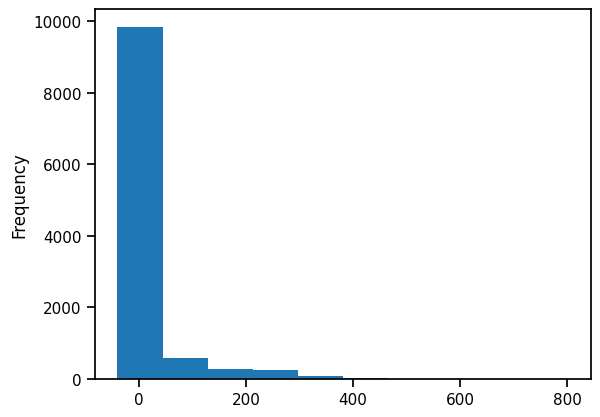

In [33]:
# trnafporm into expanstion
adata_msn.obs["expansion"] = adata_msn.obs["CAGLENGTH"] - adata_msn.obs["EXP_germline"]
adata_msn.obs["log_expansion"] = np.log1p(adata_msn.obs["expansion"])

adata_msn.obs["expansion"].plot.hist()

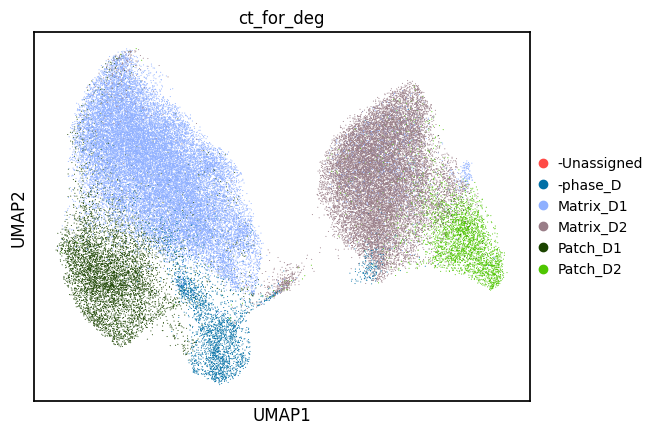

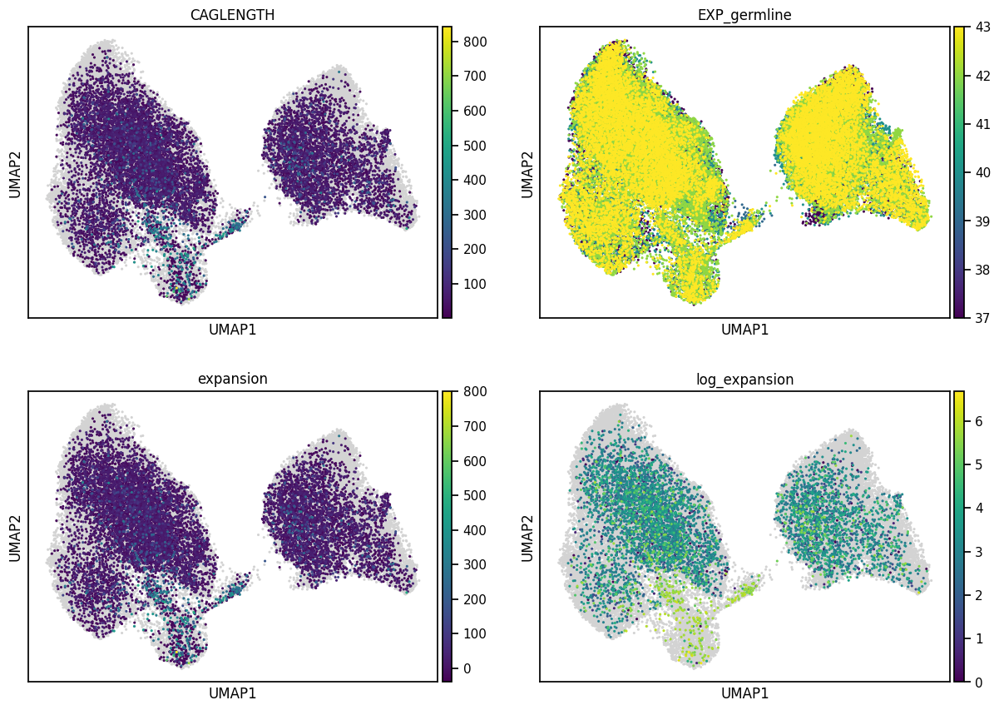

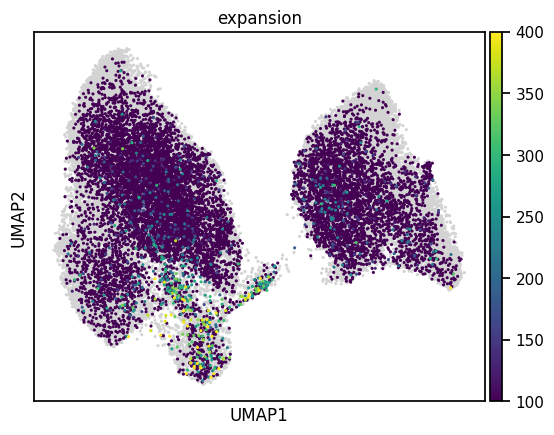

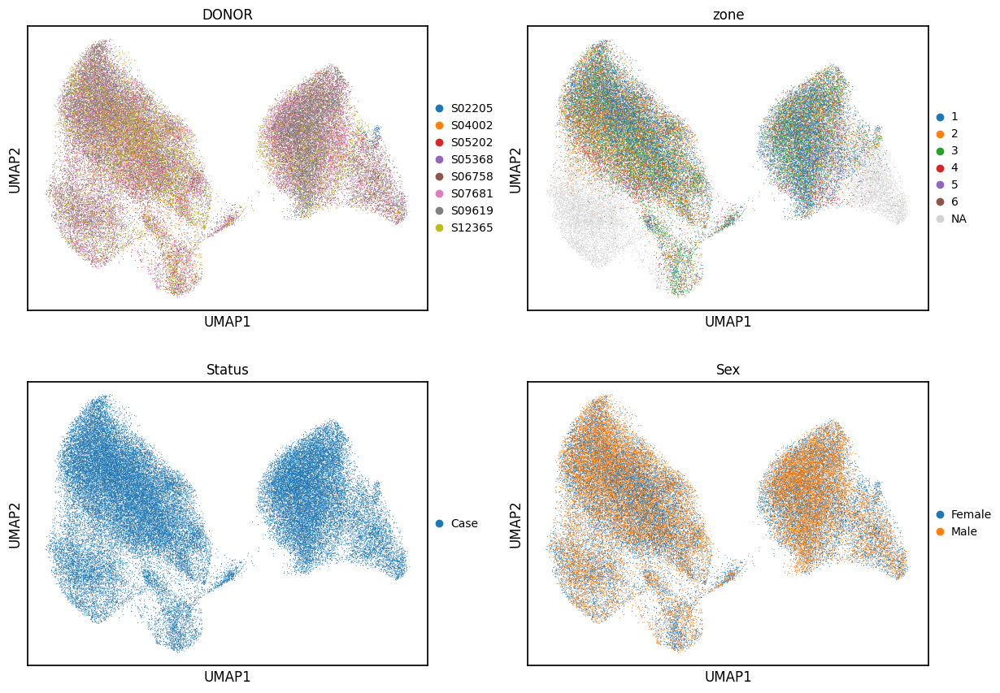

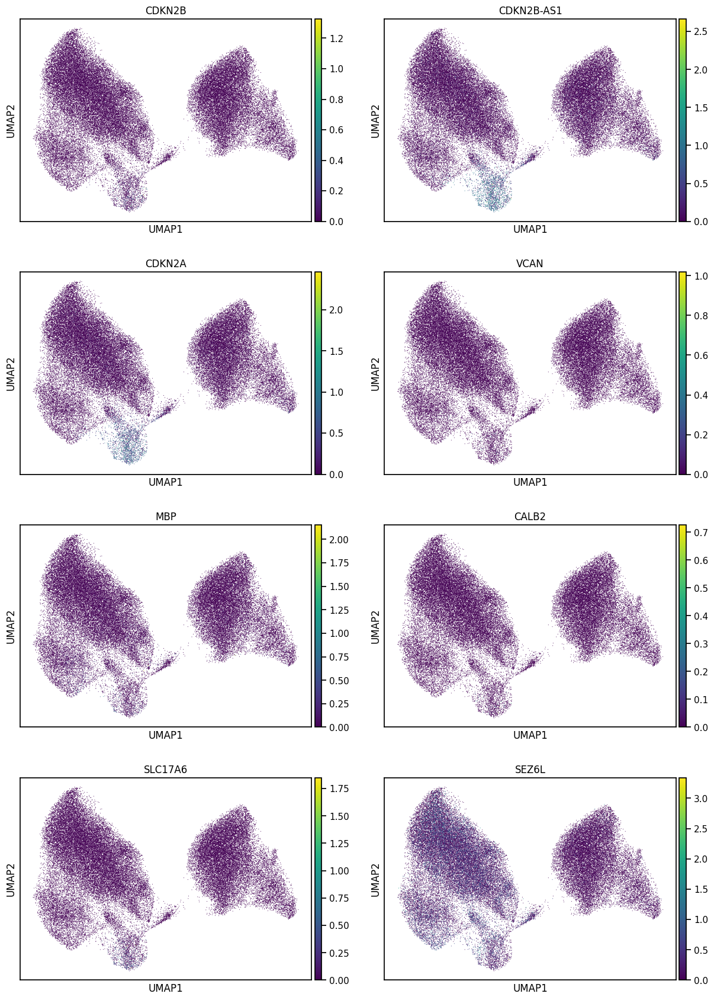

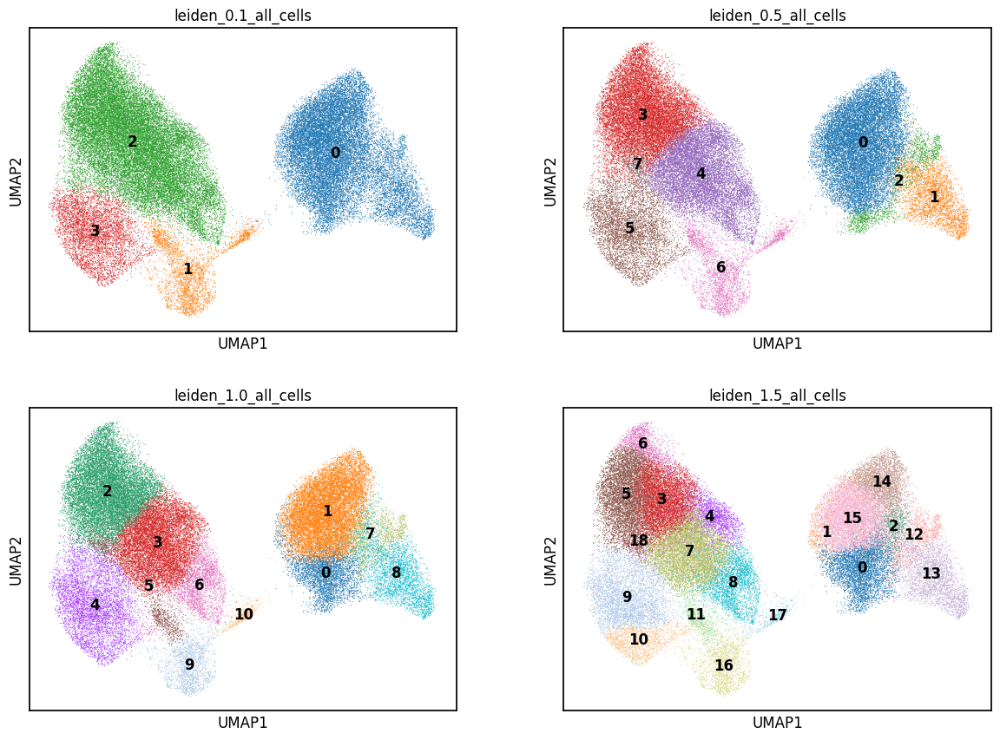

['leiden_0.1_all_cells',
 'leiden_0.5_all_cells',
 'leiden_1.0_all_cells',
 'leiden_1.5_all_cells']

In [32]:
sc.pl.umap(adata_msn,color="ct_for_deg")
sc.pl.umap(adata_msn,color=["CAGLENGTH","EXP_germline", "expansion", "log_expansion"], ncols=2, s=20)
sc.pl.umap(adata_msn,color=["expansion"], ncols=2, s=20, vmin=100, vmax=400)

sc.pl.umap(adata_msn,color=["DONOR","zone", "Status", "Sex"], ncols=2)
sc.pl.umap(adata_msn,color=["CDKN2B", "CDKN2B-AS1", "CDKN2A", "VCAN", "MBP", "CALB2", "SLC17A6", "SEZ6L"], layer="log1p_norm", ncols=2)
sc.pl.umap(adata_msn,color=leiden_cluster_names, ncols=2, legend_loc="on data")

#sc.pl.umap(adata_msn,color="Phase_D")
#sc.pl.umap(adata_msn,color="ventral_high_CAG_not_Phase_D")

leiden_cluster_names

In [14]:
# Wilcoxon
from utils import preprocessing
res = preprocessing.rank_markers_per_cluster(adata_msn, "leiden_1.5_all_cells", layer="log1p_norm", n_genes=50, markers=None)

for cluster, df in res.items():
    print(f"Cluster {cluster}:")
    df = df.merge(adata.var[["gene_symbol"]], left_on="names", right_index=True, how="left")
    display(df.head(30))

2026-11-01 20:06:13 | [INFO] cffi mode is CFFI_MODE.ANY
2026-11-01 20:06:13 | [INFO] R home found: /usr/lib/R
2026-11-01 20:06:14 | [INFO] R library path: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-11-01 20:06:14 | [INFO] LD_LIBRARY_PATH: /usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64
2026-11-01 20:06:14 | [INFO] Default options to initialize R: rpy2, --quiet, --no-save
2026-11-01 20:06:14 | [INFO] Environment variable "LD_LIBRARY_PATH" redefined by R and overriding existing variable. Current: "/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64:/usr/local/cuda-12.2/lib64", R: "/usr/lib/R/lib:/usr/lib/x86_64-linux-gnu:/home/gdallagl/myworkdir/tools/IGV_Linux_2.19.8/jdk-21/lib/server:/usr/local/cuda

Cluster 0:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,PENK,78.497658,2.416814,0.000000e+00,0.000000e+00,PENK
1,FIG4,67.755013,1.402775,0.000000e+00,0.000000e+00,FIG4
2,RABGAP1L,66.981934,0.753271,0.000000e+00,0.000000e+00,RABGAP1L
3,CHRM3,65.694176,2.091631,0.000000e+00,0.000000e+00,CHRM3
4,DRD2,64.705032,1.966393,0.000000e+00,0.000000e+00,DRD2
5,PTPRM,62.800060,1.192496,0.000000e+00,0.000000e+00,PTPRM
6,LINC01378,61.709332,1.786142,0.000000e+00,0.000000e+00,LINC01378
7,GPR6,60.906811,2.307439,0.000000e+00,0.000000e+00,GPR6
8,UTRN,57.966476,1.179072,0.000000e+00,0.000000e+00,UTRN
9,GPR88,57.084904,1.466282,0.000000e+00,0.000000e+00,GPR88


Cluster 3:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,HS6ST3,67.444336,0.905276,0.000000e+00,0.000000e+00,HS6ST3
1,DSCAM,56.424839,0.833731,0.000000e+00,0.000000e+00,DSCAM
2,EBF1,54.975971,1.349101,0.000000e+00,0.000000e+00,EBF1
3,OPCML,54.642796,0.575476,0.000000e+00,0.000000e+00,OPCML
4,MARCH1,49.333931,0.546385,0.000000e+00,0.000000e+00,MARCH1
5,ERBB4,48.980293,0.625304,0.000000e+00,0.000000e+00,ERBB4
6,CNTNAP3B,48.112598,0.924004,0.000000e+00,0.000000e+00,CNTNAP3B
7,PTCHD4,47.487091,0.968761,0.000000e+00,0.000000e+00,PTCHD4
8,ROBO2,46.898075,0.422202,0.000000e+00,0.000000e+00,ROBO2
9,SNTG1,46.114292,0.310054,0.000000e+00,0.000000e+00,SNTG1


Cluster 7:


... (29 outputs left out)

Cluster 1:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,DRD2,24.345306,2.370207,6.500538e-131,1.200747e-126,DRD2
1,SPOCK1,23.924997,1.419536,1.682864e-126,1.554251e-122,SPOCK1
2,RGS9,23.547905,1.369304,1.318984e-122,9.745443e-119,RGS9
3,AC111152.2,22.971081,3.230501,9.072627e-117,5.586168e-113,AC111152.2
4,FAM135B,22.363571,0.966883,8.909103e-111,4.701843e-107,FAM135B
5,AHI1,21.577654,0.904152,2.912778e-103,1.345084e-99,AHI1
6,GUCY1A3,21.328350,1.223585,6.195417e-101,2.288773e-97,GUCY1A3
7,ASTN2,21.252253,1.140433,3.142216e-100,9.673573e-97,ASTN2
8,TSIX,20.533482,2.377241,1.081438e-93,3.073198e-90,TSIX
9,SORCS3,20.436201,0.922303,7.970839e-93,2.103334e-89,SORCS3


Cluster 2:


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol
0,GPC5,32.089222,1.167383,6.232875e-226,2.302611e-221,GPC5
1,AC092979.1,29.472034,3.242207,6.572848e-191,1.214104e-186,AC092979.1
2,UTRN,28.822350,1.529638,1.125748e-182,1.386283e-178,UTRN
3,DRD2,27.236427,2.105138,2.406504e-163,2.222587e-159,DRD2
4,FIG4,27.199886,1.505944,6.515186e-163,4.813810e-159,FIG4
5,PCDH9,27.098112,1.470764,1.036380e-161,6.381164e-158,PCDH9
6,NTNG1,26.903996,2.097404,1.972071e-159,1.040775e-155,NTNG1
7,RABGAP1L,26.850368,0.819512,8.351445e-159,3.856593e-155,RABGAP1L
8,AC090124.2,25.303732,2.544003,2.905934e-141,1.192821e-137,AC090124.2
9,ZNF83,24.188684,1.402281,2.926701e-129,1.081211e-125,ZNF83


# Subcluster phase D

In [19]:


adata_d = adata_msn[
                adata_msn.obs["ct_for_deg"].isin(["-phase_D"]) 
                ].copy()


leiden_cluster_names = lmu.preprocess_common_pipeline(adata_d, leiden_name="_all_cells", integrate_with_harmony=True, batch_key="DONOR", 
                                                      resolutions=[0.1, 0.5, 1.0, 1.5])

Seed set to 42


Running HVG...
HVG computed with batch_key='DONOR'
Subsetting to copy with only HVG...
Scaling ...
Running Harmony...
Running PCA before Harmony...


/home/gdallagl/.pyenv/versions/3.11.8/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
2026-11-01 20:25:51,525 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-11-01 20:25:51 | [INFO] Running Harmony (PyTorch on cuda)
2026-11-01 20:25:51,527 - harmonypy - INFO -   Parameters:
2026-11-01 20:25:51 | [INFO]   Parameters:
2026-11-01 20:25:51,529 - harmonypy - INFO -     max_iter_harmony: 30
2026-11-01 20:25:51 | [INFO]     max_iter_harmony: 30
2026-11-01 20:25:51,530 - harmonypy - INFO -     max_iter_kmeans: 20
2026-11-01 20:25:51 | [INFO]     max_iter_kmeans: 20
2026-11-01 20:25:51,532 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-11-01 20:25:51 | [INFO]     epsilon_cluster: 1e-05
2026-11-01 20:25:51,533 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-11-01 20:25:51 | [INFO]     epsilon_harmony: 0.0001
2026-11-01 20:25:51,535 - harmonypy - INFO -     nclust: 94
2026-11

Running Harmony batch correction...


2026-11-01 20:25:52,015 - harmonypy - INFO - Iteration 2 of 30
2026-11-01 20:25:52 | [INFO] Iteration 2 of 30
2026-11-01 20:25:52,408 - harmonypy - INFO - Iteration 3 of 30
2026-11-01 20:25:52 | [INFO] Iteration 3 of 30
2026-11-01 20:25:52,780 - harmonypy - INFO - Iteration 4 of 30
2026-11-01 20:25:52 | [INFO] Iteration 4 of 30
2026-11-01 20:25:53,089 - harmonypy - INFO - Iteration 5 of 30
2026-11-01 20:25:53 | [INFO] Iteration 5 of 30
2026-11-01 20:25:53,328 - harmonypy - INFO - Iteration 6 of 30
2026-11-01 20:25:53 | [INFO] Iteration 6 of 30
2026-11-01 20:25:53,564 - harmonypy - INFO - Iteration 7 of 30
2026-11-01 20:25:53 | [INFO] Iteration 7 of 30
2026-11-01 20:25:53,814 - harmonypy - INFO - Iteration 8 of 30
2026-11-01 20:25:53 | [INFO] Iteration 8 of 30
2026-11-01 20:25:54,022 - harmonypy - INFO - Iteration 9 of 30
2026-11-01 20:25:54 | [INFO] Iteration 9 of 30
2026-11-01 20:25:54,209 - harmonypy - INFO - Iteration 10 of 30
2026-11-01 20:25:54 | [INFO] Iteration 10 of 30
2026-11-

Z_corr shape: (2822, 50), n_obs: 2822
Computing neighbors on Harmony-corrected PCA...
Computing UMAP...
Computing Leiden clusters...


/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


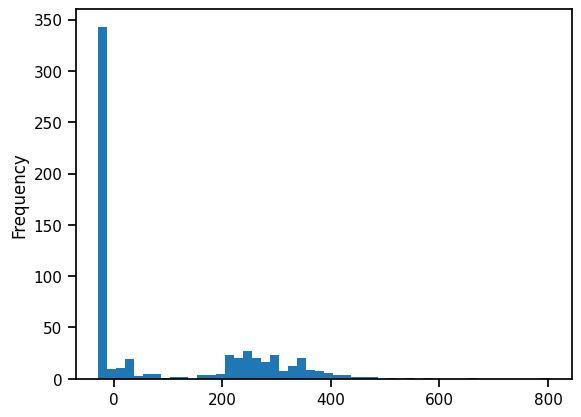

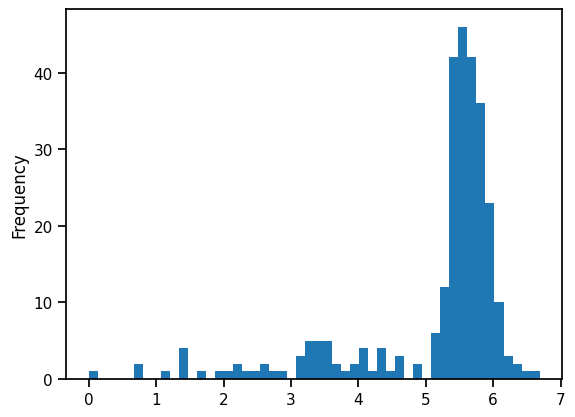

expansion_more300
NaN                    2197
Expansion_below_300     541
Expansion_above_300      84
Name: count, dtype: int64

In [106]:
# trnafporm into expanstion
adata_d.obs["expansion"] = adata_d.obs["CAGLENGTH"] - adata_d.obs["EXP_germline"]
adata_d.obs["log_expansion"] = np.log1p(adata_d.obs["expansion"])

adata_d.obs["expansion"].plot.hist(bins=50); plt.show()
adata_d.obs["log_expansion"].plot.hist(bins=50); plt.show()


exp = adata_d.obs["expansion"]

adata_d.obs["expansion_more150"] = pd.cut(
    exp,
    bins=[-np.inf, 150, np.inf],                          # (-inf, 150] and (150, inf)
    labels=["Expansion_below_150", "Expansion_above_150"],
)   # no expansion -> NaN

adata_d.obs["expansion_more150"].value_counts(dropna=False)

adata_d.obs["expansion_more300"] = pd.cut(
    exp,
    bins=[-np.inf, 300, np.inf],                          # (-inf, 300] and (300, inf)
    labels=["Expansion_below_300", "Expansion_above_300"],
)   # no expansion -> NaN

adata_d.obs["expansion_more300"].value_counts(dropna=False)


In [73]:
adata_d

AnnData object with n_obs × n_vars = 2822 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zone_

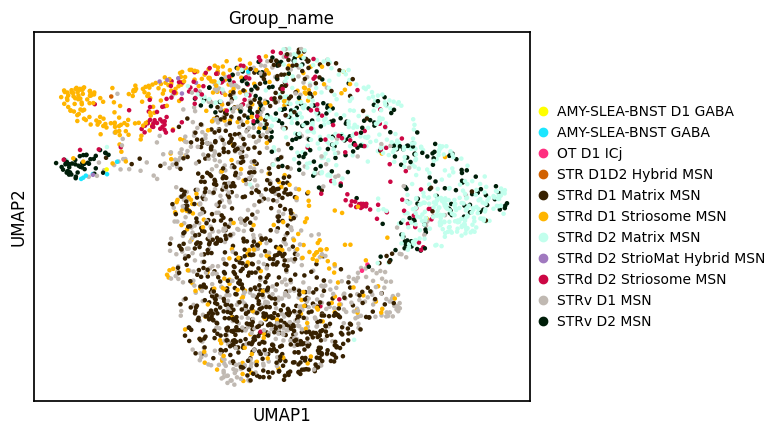

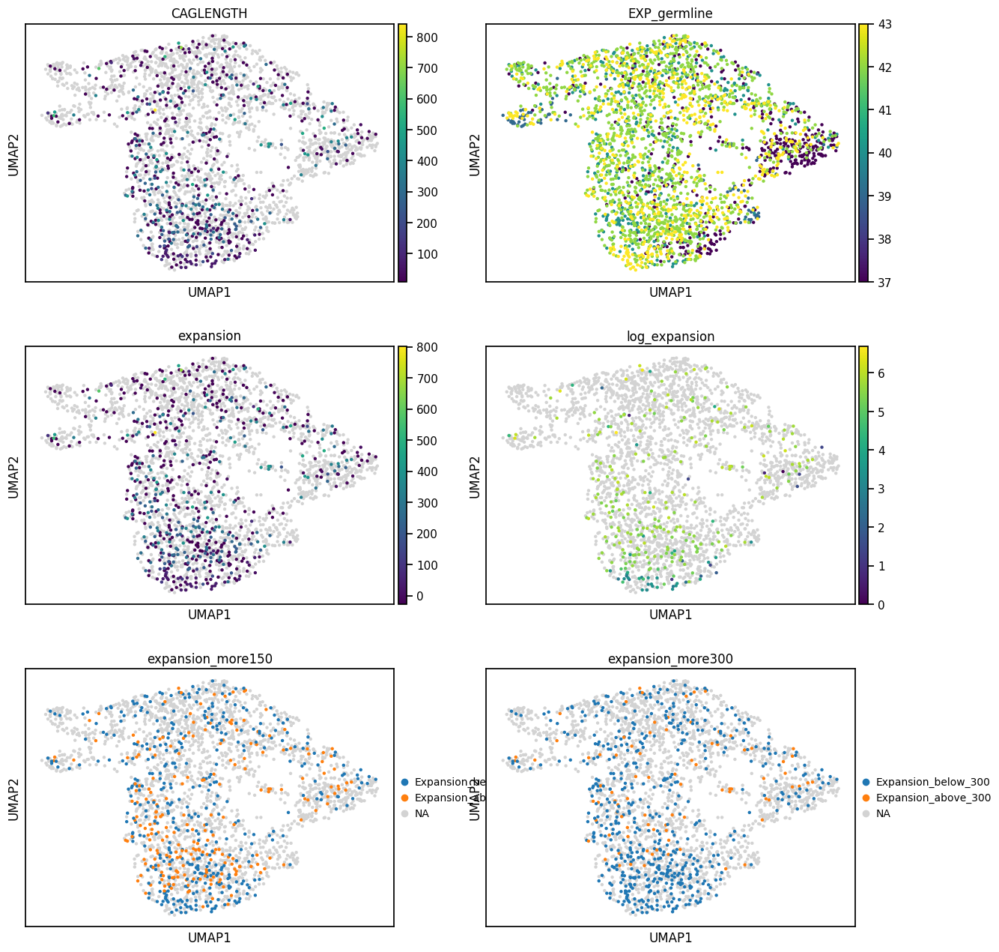

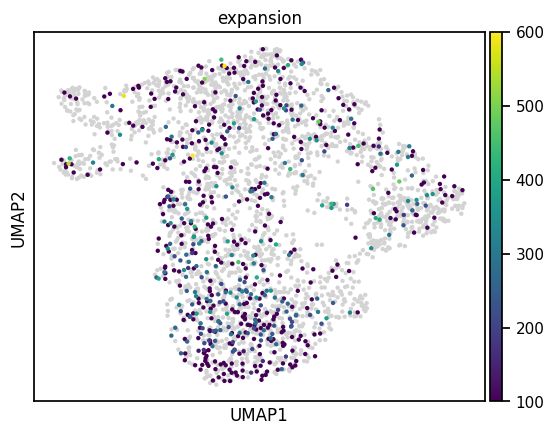

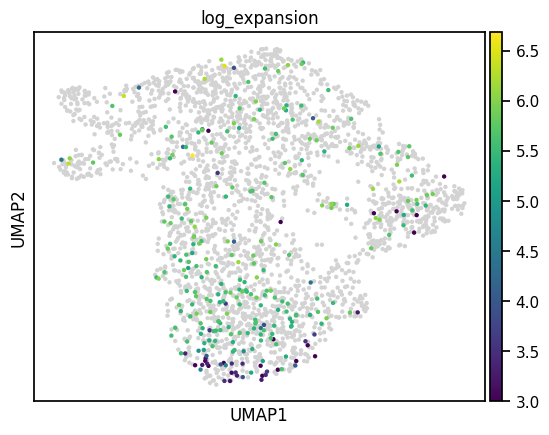

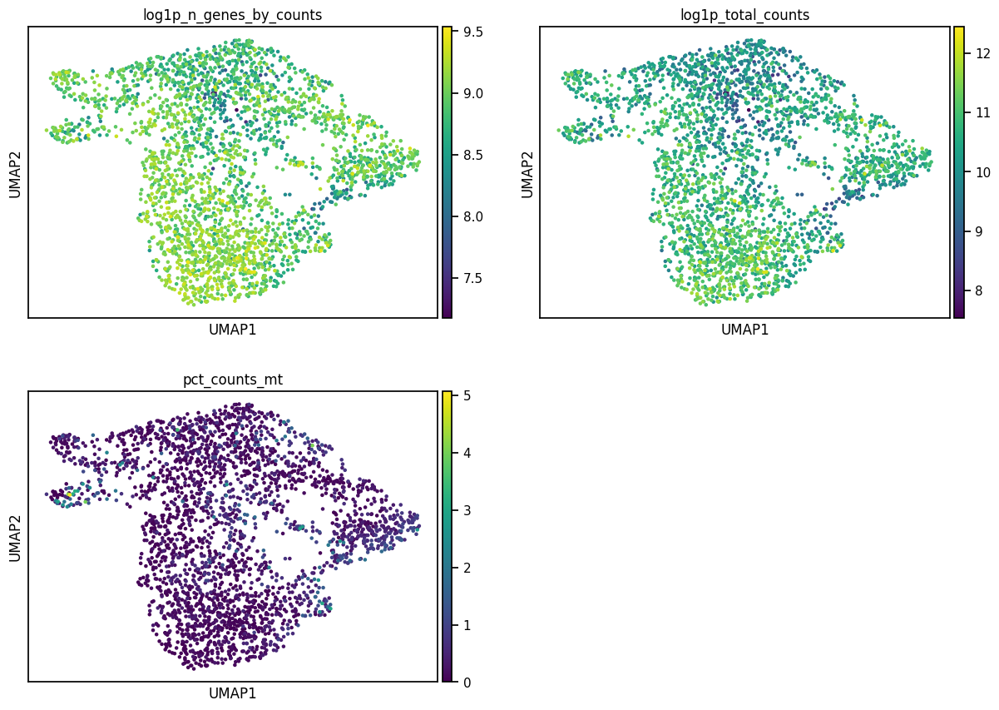

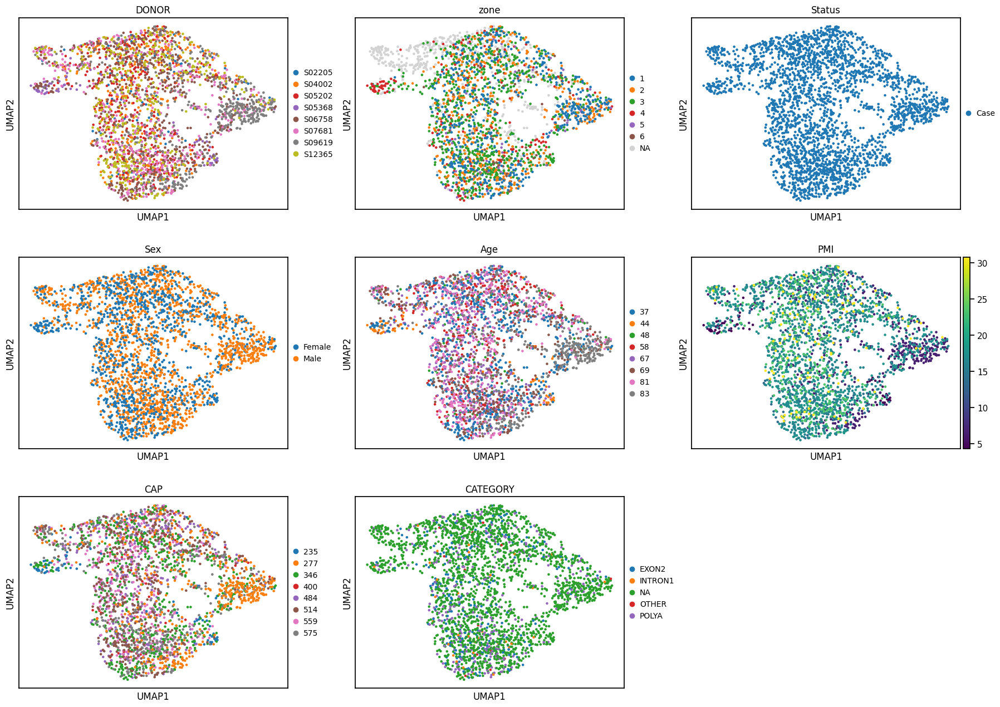

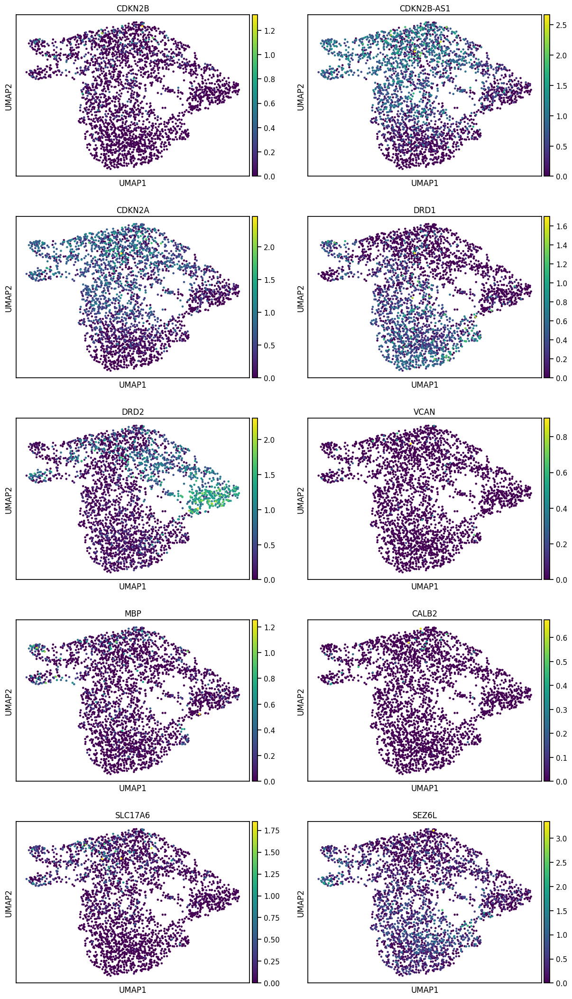

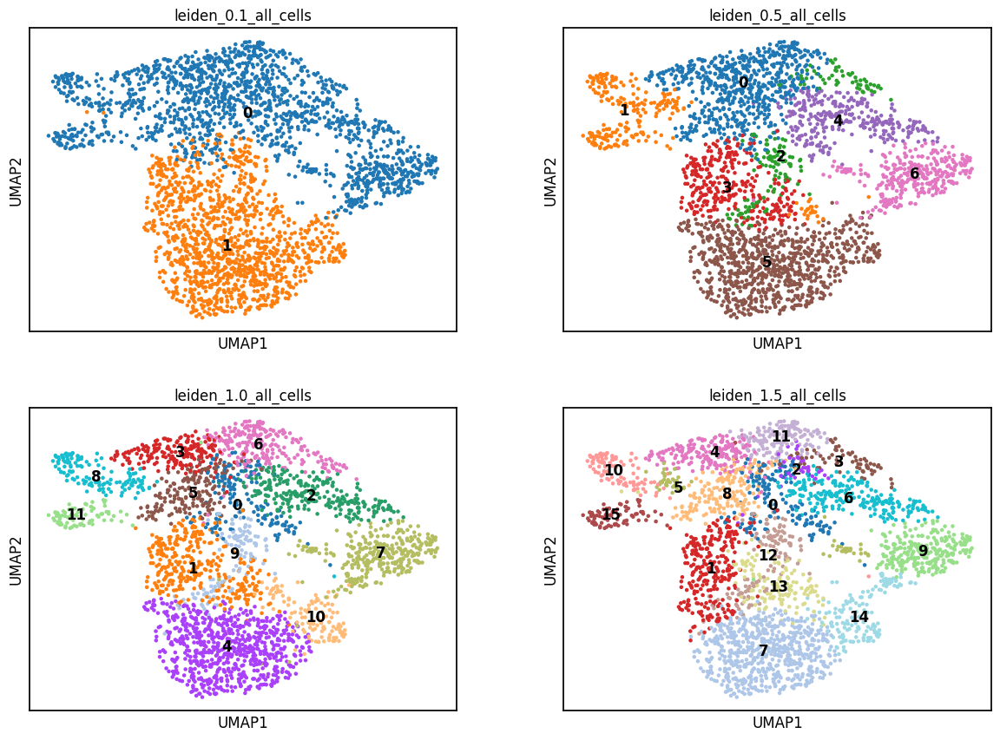

['leiden_0.1_all_cells',
 'leiden_0.5_all_cells',
 'leiden_1.0_all_cells',
 'leiden_1.5_all_cells']

In [107]:
sc.pl.umap(adata_d,color=["Group_name"])

sc.pl.umap(adata_d,color=["CAGLENGTH","EXP_germline", "expansion", "log_expansion", "expansion_more150", "expansion_more300"], ncols=2, s=40)
sc.pl.umap(adata_d,color=["expansion"], ncols=2, s=40, vmin=100, vmax=600)
sc.pl.umap(adata_d,color=["log_expansion"], ncols=2, s=40, vmin=3, )

sc.pl.umap(adata_d, color=["log1p_n_genes_by_counts", "log1p_total_counts", "pct_counts_mt"], legend_loc="on data", ncols=2)


sc.pl.umap(adata_d,color=["DONOR","zone", "Status", "Sex", "Age", "PMI", "CAP", "CATEGORY"], ncols=3)

sc.pl.umap(adata_d,color=["CDKN2B", "CDKN2B-AS1","CDKN2A",
                          "DRD1", "DRD2",
                           "VCAN", "MBP", "CALB2", "SLC17A6", "SEZ6L"], layer="log1p_norm", ncols=2)
sc.pl.umap(adata_d,color=leiden_cluster_names, ncols=2, legend_loc="on data")

#sc.pl.umap(adata_msn,color="Phase_D")
#sc.pl.umap(adata_msn,color="ventral_high_CAG_not_Phase_D")

leiden_cluster_names

... storing 'phase_D_label' as categorical


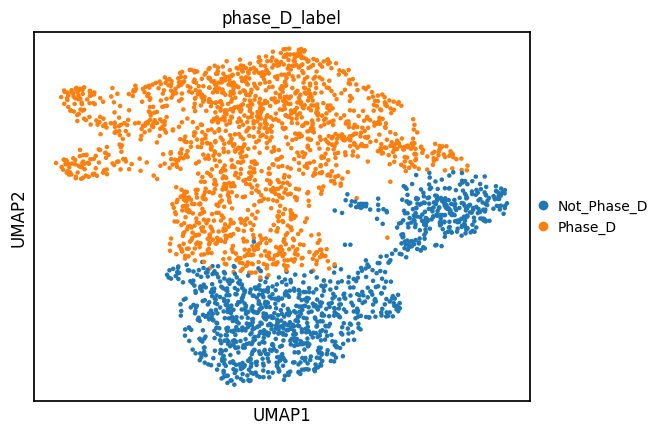

In [ ]:
adata_d.obs["phase_D_label"] = np.where(
    adata_d.obs["leiden_0.5_all_cells"].isin(["5", "6"]), "Not_Phase_D", "Phase_D"
    )
sc.pl.umap(adata_d, color="phase_D_label", ncols=2)

In [56]:
import importlib; importlib.reload(preprocessing)

# DE: both directions, expression filter only
res = preprocessing.wilcoxon_deg_per_cluster(
    adata_d, "phase_D_label", layer="log1p_norm", gene_symbols="gene_symbol"
)

for cluster, d in res.items():
    print(f"Cluster {cluster}: {len(d['up'])} up, {len(d['down'])} down")
    display(d["up"].head(30))
    display(d["down"].head(30))

# full table for one cluster (volcano plots, GSEA ranking, ...)
#res["3"]["all"]


Cluster Not_Phase_D: 1830 up, 2569 down


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,SLC35F3,37.535492,1.303020,2.429719e-308,8.976110e-304,SLC35F3,1.000000,0.996990
1,FAT3,35.501930,1.208698,4.589428e-276,8.477363e-272,FAT3,0.998277,0.983745
2,PDZD2,33.556824,1.178596,7.159519e-247,8.816471e-243,PDZD2,1.000000,0.984347
3,PHACTR1,33.159698,0.819751,4.105085e-241,3.791354e-237,PHACTR1,1.000000,1.000000
4,RAPGEF5,31.959753,1.047255,3.954791e-224,2.435031e-220,RAPGEF5,1.000000,0.981337
5,CAMK4,31.620470,0.905501,1.931897e-219,1.019572e-215,CAMK4,0.999139,0.993980
6,AC109466.1,30.848051,1.603267,5.949269e-209,2.747298e-205,AC109466.1,0.995693,0.918724
7,DCC,30.634382,1.066977,4.266899e-206,1.751467e-202,DCC,1.000000,0.982541
8,PPP3CA,30.379185,0.824629,1.034690e-202,3.822455e-199,PPP3CA,1.000000,0.998796
9,ATP2B1,30.323034,1.134631,5.698620e-202,1.913856e-198,ATP2B1,0.999139,0.985551


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,NRXN3,-33.147984,-0.593796,6.055354e-241,4.474059e-237,NRXN3,1.000000,1.000000
1,FTX,-28.354708,-0.531564,7.322926e-177,1.127212e-173,FTX,0.999139,1.000000
2,TBX5,-28.339285,-4.532096,1.134468e-176,1.676427e-173,TBX5,0.072351,0.668874
3,CDKN2A,-27.849386,-2.568071,1.095723e-170,1.305783e-167,CDKN2A,0.260982,0.777845
4,CDKN2B-AS1,-27.781427,-2.553992,7.273108e-170,8.396576e-167,CDKN2B-AS1,0.273902,0.786875
5,TNRC6A,-27.583908,-0.620740,1.735631e-167,1.831984e-164,TNRC6A,0.999139,0.999398
6,HOXD3,-27.213921,-4.479956,4.444991e-163,4.561425e-160,HOXD3,0.055125,0.639374
7,AC098829.1,-26.138018,-1.931329,1.348710e-150,1.132395e-147,AC098829.1,0.788975,0.925948
8,C14orf39,-25.922800,-4.049186,3.685617e-148,2.959951e-145,C14orf39,0.090439,0.632149
9,PCNX2,-25.268200,-0.608898,7.146432e-141,5.280213e-138,PCNX2,0.998277,0.996388


Cluster Phase_D: 2569 up, 1830 down


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,NRXN3,33.147984,0.593796,6.055354e-241,4.474059e-237,NRXN3,1.000000,1.000000
1,FTX,28.354708,0.531564,7.322926e-177,1.127212e-173,FTX,1.000000,0.999139
2,TBX5,28.339285,4.532096,1.134468e-176,1.676427e-173,TBX5,0.668874,0.072351
3,CDKN2A,27.849386,2.568071,1.095723e-170,1.305783e-167,CDKN2A,0.777845,0.260982
4,CDKN2B-AS1,27.781427,2.553992,7.273108e-170,8.396576e-167,CDKN2B-AS1,0.786875,0.273902
5,TNRC6A,27.583908,0.620740,1.735631e-167,1.831984e-164,TNRC6A,0.999398,0.999139
6,HOXD3,27.213921,4.479956,4.444991e-163,4.561425e-160,HOXD3,0.639374,0.055125
7,AC098829.1,26.138018,1.931329,1.348710e-150,1.132395e-147,AC098829.1,0.925948,0.788975
8,C14orf39,25.922800,4.049186,3.685617e-148,2.959951e-145,C14orf39,0.632149,0.090439
9,PCNX2,25.268200,0.608898,7.146432e-141,5.280213e-138,PCNX2,0.996388,0.998277


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,SLC35F3,-37.535492,-1.303020,2.429719e-308,8.976110e-304,SLC35F3,0.996990,1.000000
1,FAT3,-35.501930,-1.208698,4.589428e-276,8.477363e-272,FAT3,0.983745,0.998277
2,PDZD2,-33.556824,-1.178596,7.159519e-247,8.816471e-243,PDZD2,0.984347,1.000000
3,PHACTR1,-33.159698,-0.819751,4.105085e-241,3.791354e-237,PHACTR1,1.000000,1.000000
4,RAPGEF5,-31.959753,-1.047255,3.954791e-224,2.435031e-220,RAPGEF5,0.981337,1.000000
5,CAMK4,-31.620470,-0.905501,1.931897e-219,1.019572e-215,CAMK4,0.993980,0.999139
6,AC109466.1,-30.848051,-1.603267,5.949269e-209,2.747298e-205,AC109466.1,0.918724,0.995693
7,DCC,-30.634382,-1.066977,4.266899e-206,1.751467e-202,DCC,0.982541,1.000000
8,PPP3CA,-30.379185,-0.824629,1.034690e-202,3.822455e-199,PPP3CA,0.998796,1.000000
9,ATP2B1,-30.323034,-1.134631,5.698620e-202,1.913856e-198,ATP2B1,0.985551,0.999139


In [47]:
import importlib; importlib.reload(preprocessing)

# DE: both directions, expression filter only
res = preprocessing.wilcoxon_deg_per_cluster(
    adata_d, "leiden_0.5_all_cells", layer="log1p_norm", gene_symbols="gene_symbol"
)

for cluster, d in res.items():
    print(f"Cluster {cluster}: {len(d['up'])} up, {len(d['down'])} down")
    display(d["up"].head(30))
    display(d["down"].head(30))

# full table for one cluster (volcano plots, GSEA ranking, ...)
res["3"]["all"]


Cluster 0: 2001 up, 2388 down


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,NRXN3,26.182825,0.584596,4.169658e-151,1.925496e-147,NRXN3,1.000000,1.000000
1,TNRC6A,25.390615,0.713890,3.201712e-142,8.448632e-139,TNRC6A,1.000000,0.999084
2,AC098829.1,23.358864,1.896983,1.120028e-120,1.088874e-117,AC098829.1,0.937402,0.849748
3,FTX,23.245422,0.512284,1.582547e-119,1.461601e-116,FTX,1.000000,0.999542
4,AHI1,22.318272,0.818502,2.456031e-110,2.110074e-107,AHI1,0.996870,0.995419
5,HIBCH,22.125340,1.336634,1.802779e-108,1.513638e-105,HIBCH,0.965571,0.952817
6,LRP2BP,21.842869,1.539741,9.086766e-106,6.850866e-103,LRP2BP,0.924883,0.807604
7,AC016831.1,21.641352,0.992780,7.332151e-104,4.924939e-101,AC016831.1,0.968701,0.973889
8,LINC01359,21.485460,1.427875,2.129421e-102,1.380127e-99,LINC01359,0.902973,0.751260
9,HOXD10,21.421535,2.501510,8.416705e-102,5.361006e-99,HOXD10,0.719875,0.187357


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,LRRC7,-29.208633,-0.861811,1.506582e-187,5.565767e-183,LRRC7,0.996870,1.000000
1,CNKSR2,-28.990005,-1.428564,8.794498e-185,1.624476e-180,CNKSR2,0.928013,0.997251
2,FAT3,-27.382566,-1.302873,4.424000e-165,5.447861e-161,FAT3,0.964006,0.997251
3,RAPGEF5,-27.168491,-1.200632,1.531308e-162,1.414277e-158,RAPGEF5,0.959311,0.997710
4,PPP3CA,-26.737112,-0.900254,1.743741e-157,1.288381e-153,PPP3CA,0.996870,1.000000
5,ARAP2,-26.702639,-1.390815,4.386176e-157,2.700642e-153,ARAP2,0.892019,0.993129
6,SYNPR,-26.439157,-1.682176,4.862331e-154,2.566130e-150,SYNPR,0.740219,0.979844
7,SLC35F3,-26.072723,-1.133155,7.434633e-150,3.051752e-146,SLC35F3,0.992175,1.000000
8,MALAT1,-25.917301,-0.895236,4.250965e-148,1.570434e-144,MALAT1,1.000000,1.000000
9,TLE4,-25.829391,-1.427691,4.147349e-147,1.392868e-143,TLE4,0.857590,0.987632


Cluster 1: 1013 up, 693 down


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,LSAMP,17.146812,0.799682,6.639612e-66,2.452872e-61,LSAMP,1.000000,0.998841
1,BACH2,16.742235,2.681466,6.452030e-63,1.191787e-58,BACH2,0.850427,0.358964
2,FHOD3,15.911589,3.166001,5.266037e-57,6.484774e-53,FHOD3,0.747863,0.210201
3,GRIA1,14.897964,0.710302,3.397718e-50,3.138047e-46,GRIA1,1.000000,0.988408
4,KCNIP1,14.674814,2.258169,9.347095e-49,6.906195e-45,KCNIP1,0.820513,0.382148
5,AC092691.1,13.739903,0.849678,5.855408e-43,2.703954e-39,AC092691.1,1.000000,0.986862
6,MGAT4C,13.410769,1.436681,5.229319e-41,1.756243e-37,MGAT4C,0.965812,0.799073
7,AC007091.1,13.039578,2.007082,7.285878e-39,2.070478e-35,AC007091.1,0.803419,0.331144
8,ATP2B4,12.751497,1.654501,3.058127e-37,8.069743e-34,ATP2B4,0.833333,0.507342
9,RIMS2,12.581967,0.391176,2.653395e-36,6.534957e-33,RIMS2,1.000000,1.000000


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,STXBP6,-14.372323,-2.276032,7.719733e-47,4.753168e-43,STXBP6,0.329060,0.785549
1,KIRREL3,-13.818951,-1.235812,1.959054e-43,1.033905e-39,KIRREL3,0.944444,0.973725
2,SAMD5,-13.673675,-2.477114,1.458410e-42,5.986448e-39,SAMD5,0.333333,0.735317
3,ZNF385B,-13.445539,-1.283722,3.270148e-41,1.208091e-37,ZNF385B,0.914530,0.973725
4,AL033504.1,-13.101828,-2.472917,3.214232e-39,9.895282e-36,AL033504.1,0.252137,0.696677
5,ADAM12,-12.511214,-1.678400,6.482578e-36,1.408741e-32,ADAM12,0.517094,0.801777
6,DCC,-12.273821,-1.042355,1.252026e-34,2.569644e-31,DCC,0.952991,0.993045
7,PTCHD4,-11.980588,-2.529875,4.491288e-33,7.213986e-30,PTCHD4,0.162393,0.607805
8,HTR4,-11.749017,-0.894465,7.144497e-32,1.055757e-28,HTR4,0.901709,0.950155
9,SLC35F3,-11.566040,-0.816827,6.124496e-31,7.801974e-28,SLC35F3,1.000000,0.998068


... (12 outputs left out)

Cluster 6: 1042 up, 3290 down


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,PTPRM,24.544521,2.005211,4.948629e-133,1.828172e-128,PTPRM,0.990712,0.918367
1,DRD2,24.339115,3.101828,7.559629e-131,1.396377e-126,DRD2,0.947368,0.373749
2,CHRM3,23.192924,2.758374,5.366885e-119,6.608961e-115,CHRM3,0.984520,0.599840
3,PENK,22.974058,3.964796,8.471942e-117,7.824474e-113,PENK,0.876161,0.279312
4,GPR88,19.410631,2.792753,6.275062e-84,4.636393e-80,GPR88,0.891641,0.614646
5,NDST3,18.855444,1.217056,2.651080e-79,1.632314e-75,NDST3,0.996904,0.963185
6,LINC01378,18.754391,2.318602,1.782479e-78,9.407158e-75,LINC01378,0.897833,0.539016
7,RABGAP1L,18.334000,0.662368,4.430974e-75,2.046168e-71,RABGAP1L,0.996904,0.997199
8,HPCA,18.240929,2.211746,2.442695e-74,9.024046e-71,HPCA,0.913313,0.715486
9,FIG4,18.158310,1.382609,1.103710e-73,3.706760e-70,FIG4,0.944272,0.813125


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,FOXP2,-18.287119,-3.285385,1.048091e-74,4.302179e-71,FOXP2,0.232198,0.752301
1,DSCAM,-18.076090,-1.411504,4.917476e-73,1.513886e-69,DSCAM,0.894737,0.958383
2,RELN,-17.966002,-2.541773,3.597238e-72,9.492342e-69,RELN,0.374613,0.799120
3,HS6ST3,-17.812990,-1.208746,5.603451e-71,1.293802e-67,HS6ST3,0.978328,0.976791
4,FTX,-17.513317,-0.620110,1.133902e-68,2.464103e-65,FTX,0.996904,1.000000
5,EBF1,-17.109253,-4.178808,1.266128e-65,2.126116e-62,EBF1,0.083591,0.641857
6,NRXN3,-16.542128,-0.493777,1.824651e-61,2.324417e-58,NRXN3,1.000000,1.000000
7,LINC01481,-16.117199,-1.521181,1.931674e-58,2.098878e-55,LINC01481,0.835913,0.972389
8,AL589740.1,-15.895284,-0.855251,6.831872e-57,6.821348e-54,AL589740.1,0.975232,0.992797
9,CNTNAP2,-15.890022,-0.616242,7.430123e-57,7.223448e-54,CNTNAP2,1.000000,0.999600


,names,scores,logfoldchanges,pvals,pvals_adj,gene_symbol,pct_nz_group,pct_nz_reference
0,DSCAM,13.343693,0.881741,1.289119e-40,4.762393e-36,DSCAM,1.000000,0.944844
1,HS6ST3,12.695817,0.848913,6.237533e-37,1.152166e-32,HS6ST3,1.000000,0.974021
2,CNTNAP3B,11.696516,0.922177,1.327946e-31,1.635276e-27,CNTNAP3B,0.965625,0.754197
3,ROBO2,11.047875,0.483696,2.244645e-28,2.073098e-24,ROBO2,1.000000,1.000000
4,GDNF-AS1,10.064131,0.843954,7.958753e-24,5.880404e-20,GDNF-AS1,0.956250,0.708633
...,...,...,...,...,...,...,...,...
36938,MT-CO2,-8.743896,-1.121182,2.252050e-18,5.942679e-15,MT-CO2,0.840625,0.879696
36939,DRD2,-9.116235,-2.741948,7.777953e-20,2.394508e-16,DRD2,0.221875,0.467226
36940,MT-ND4,-9.388530,-1.331841,6.084350e-21,2.247742e-17,MT-ND4,0.725000,0.812550
36941,KCNAB1,-9.767499,-0.548881,1.552373e-22,7.168666e-19,KCNAB1,0.984375,0.989209


Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

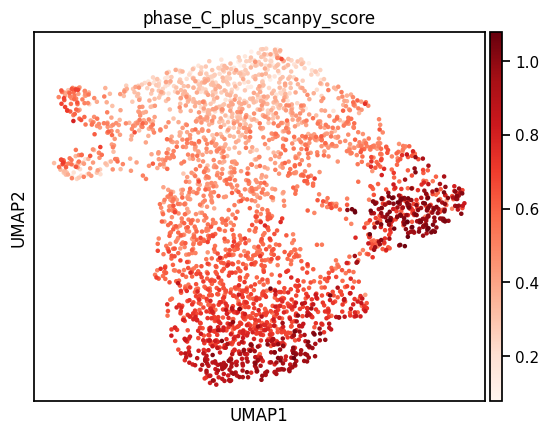

In [ ]:
# Check if they are ooligos contamiantion
df_Cminus = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all/phase_c_minus_genes.csv")
df_Cminus
dict_oligo={"phase_C_minus_scanpy": df_Cminus["Gene"].tolist()}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_d, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap")

Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

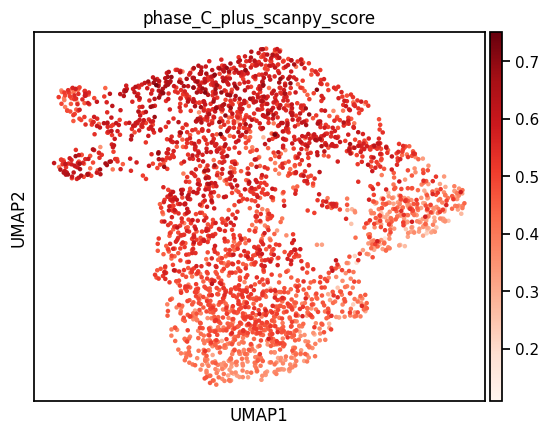

In [111]:
# Check if they are ooligos contamiantion
df_Cplus = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all/phase_c_plus_genes.csv")
df_Cplus
dict_oligo={"phase_C_plus_scanpy": df_Cplus["Gene"].tolist()}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_d, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap")

Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

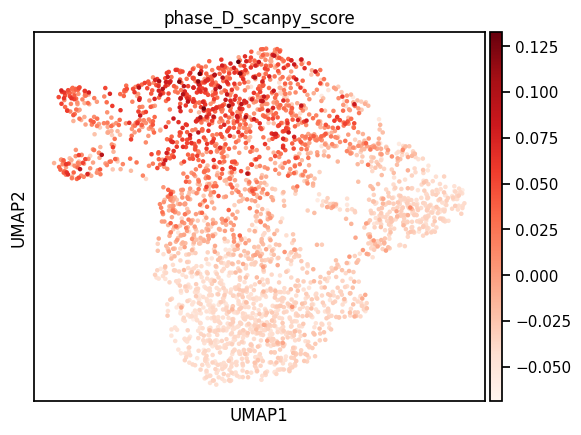

Mapped 107/107 genes for phase_D_aucell


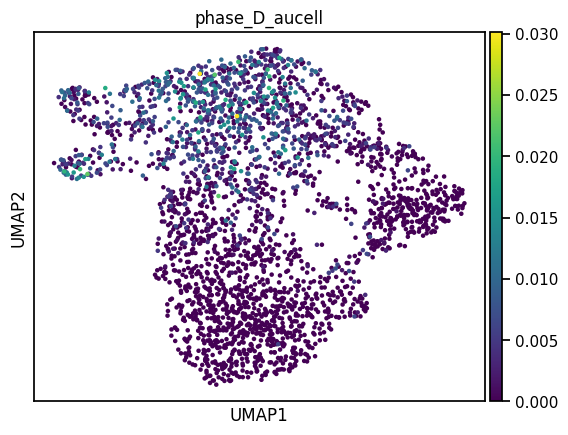

In [91]:
# Check if they are ooligos contamiantion
df_D = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all/phase_d_genes.csv")
df_D
dict_oligo={"phase_D_scanpy": df_D["Gene"].tolist()}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_d, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap")

lmu.aucell(adata_d, df_D["Gene"].tolist(), "phase_D_aucell_score")
sc.pl.umap(adata_d, color="phase_D_aucell_score", ncols=5, legend_loc=None)

In [94]:
import pandas as pd

# 1. donor/sample composition
print(pd.crosstab(adata_d.obs["DONOR"], adata_d.obs["phase_D_label"], normalize="index"))

# 2. quality/depth
print(adata_d.obs.groupby("phase_D_label")[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].median())

# 3. CAG-measurement rate per group (proxy for depth/HTT capture)
print(pd.crosstab(adata_d.obs["phase_D_label"], adata_d.obs["expansion_more150"], normalize="index"))

phase_D_label  Not_Phase_D   Phase_D
DONOR                               
S02205            0.256410  0.743590
S04002            0.293103  0.706897
S05202            0.304348  0.695652
S05368            0.340909  0.659091
S06758            0.427230  0.572770
S07681            0.485149  0.514851
S09619            0.638826  0.361174
S12365            0.326531  0.673469
               total_counts  n_genes_by_counts  pct_counts_mt
phase_D_label                                                
Not_Phase_D         47506.0             8130.0       0.171896
Phase_D             30795.0             7250.0       0.135975
expansion_more150  Expansion_below_150  Expansion_above_150
phase_D_label                                              
Not_Phase_D                   0.590000             0.410000
Phase_D                       0.689231             0.310769


/tmp/ipykernel_955262/943573542.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(adata_d.obs.groupby("phase_D_label")[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].median())


In [95]:
import pandas as pd

covs = ["Group_name", "DONOR", "zone", "Status", "Sex", "Age", "PMI", "CAP", "CATEGORY",
        "CAGLENGTH", "expansion_more150", "log1p_total_counts", "pct_counts_mt"]

for c in covs:
    x = adata_d.obs[c]
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > 10:   # numeric -> 4 bins
        x = pd.qcut(x, 4, duplicates="drop")
    ct = pd.crosstab(x, adata_d.obs["phase_D_label"])
    print(f"\n===== {c} =====")
    print(pd.concat([ct, ct.div(ct.sum(1), axis=0).round(2).add_prefix("frac_")], axis=1))


===== Group_name =====
phase_D_label                Not_Phase_D  Phase_D  frac_Not_Phase_D  \
Group_name                                                            
AMY-SLEA-BNST D1 GABA                  0        1              0.00   
AMY-SLEA-BNST GABA                     0        7              0.00   
OT D1 ICj                              2        0              1.00   
STR D1D2 Hybrid MSN                    0        1              0.00   
STRd D1 Matrix MSN                   464      387              0.55   
STRd D1 Striosome MSN                 85      318              0.21   
STRd D2 Matrix MSN                   210      266              0.44   
STRd D2 StrioMat Hybrid MSN            0        6              0.00   
STRd D2 Striosome MSN                 35      117              0.23   
STRv D1 MSN                          304      342              0.47   
STRv D2 MSN                           61      216              0.22   

phase_D_label                frac_Phase_D  
Group_na

phase_D_label                                    Not_Phase_D  Phase_D
depth_bin                   expansion_more150                        
(7.5329999999999995, 9.982] Expansion_below_150         0.13     0.87
                            Expansion_above_150         0.13     0.87
(9.982, 10.499]             Expansion_below_150         0.22     0.78
                            Expansion_above_150         0.30     0.70
(10.499, 10.948]            Expansion_below_150         0.39     0.61
                            Expansion_above_150         0.50     0.50
(10.948, 12.445]            Expansion_below_150         0.63     0.37
                            Expansion_above_150         0.69     0.31


TypeError: Invalid object type at position 0

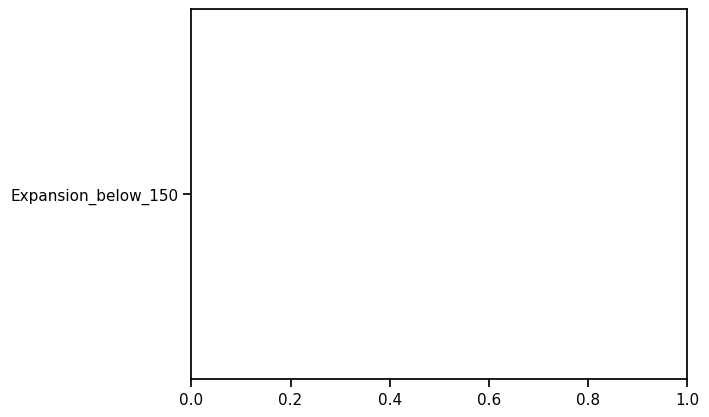

In [101]:
obs = adata_d.obs
obs["depth_bin"] = pd.qcut(obs["log1p_total_counts"], 4)
print(pd.crosstab([obs["depth_bin"], obs["expansion_more150"]], obs["phase_D_label"], normalize="index").round(2))
sns.scatterplot(obs, x="depth_bin", y="expansion_more150", hue="phase_D_label")

In [97]:
import statsmodels.formula.api as smf
sc.tl.score_genes(adata_d, ["CDKN2A", "CDKN2B", "CDKN2B-AS1"], score_name="derep")
m = adata_d.obs.query("CAGLENGTH > 35").copy()
print(smf.ols("derep ~ np.log(CAGLENGTH) + log1p_total_counts", data=m).fit().summary().tables[1])

                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.0901      2.699      0.033      0.973      -5.222       5.402
np.log(CAGLENGTH)      1.0564      0.188      5.634      0.000       0.687       1.426
log1p_total_counts    -0.5163      0.216     -2.392      0.017      -0.941      -0.091


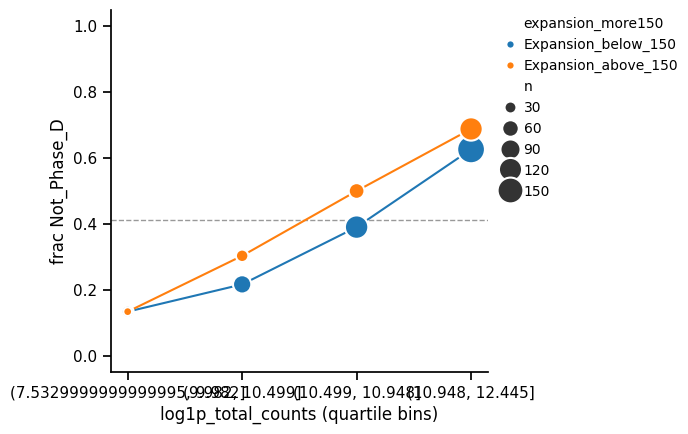

In [102]:
target = "Not_Phase_D"   # the y-axis shows the fraction of THIS label

obs = adata_d.obs
obs["depth_bin"] = pd.qcut(obs["log1p_total_counts"], 4)

# fraction of target + n cells per (depth bin, expansion group); NaN expansion dropped
df = (obs.groupby(["depth_bin", "expansion_more150"], observed=True)["phase_D_label"]
         .agg(frac=lambda s: (s == target).mean(), n="size")
         .reset_index())
df["depth_bin"] = df["depth_bin"].astype(str)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.lineplot(df, x="depth_bin", y="frac", hue="expansion_more150", legend=False, ax=ax)
sns.scatterplot(df, x="depth_bin", y="frac", hue="expansion_more150", size="n",
                sizes=(40, 400), edgecolor="white", linewidth=1.5, zorder=3, ax=ax)
ax.axhline((obs["phase_D_label"] == target).mean(), color="0.6", ls="--", lw=1, zorder=0)

ax.set(ylim=(-0.05, 1.05), xlabel="log1p_total_counts (quartile bins)", ylabel=f"frac {target}")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()


In [103]:
m["CAG_bin"] = pd.cut(m["CAGLENGTH"], [35, 100, 150, 300, 1000])
print(m.groupby("CAG_bin", observed=True)["derep"].agg(["count", "mean", "median"]))

print(smf.ols("derep ~ np.log(CAGLENGTH) + log1p_total_counts + C(DONOR)", data=m).fit().summary().tables[1])

sc.tl.score_genes(adata_d, ["HOXD3", "HOXD10", "TBX5", "TWIST1", "HAND2-AS1", "C14orf39"], score_name="hox")
m["hox"] = adata_d.obs.loc[m.index, "hox"]
print(smf.ols("hox ~ np.log(CAGLENGTH) + log1p_total_counts + C(DONOR)", data=m).fit().summary().tables[1])

             count      mean    median
CAG_bin                               
(35, 100]       46 -1.093406 -1.330000
(100, 150]      10 -0.234667 -0.111667
(150, 300]      92 -0.451594 -0.988333
(300, 1000]    134  1.160697  0.595000
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -1.1235      3.253     -0.345      0.730      -7.528       5.281
C(DONOR)[T.S04002]     0.1664      1.059      0.157      0.875      -1.919       2.252
C(DONOR)[T.S05202]     1.0295      0.549      1.874      0.062      -0.052       2.111
C(DONOR)[T.S05368]     0.3631      1.530      0.237      0.813      -2.648       3.374
C(DONOR)[T.S06758]    -0.5803      0.526     -1.103      0.271      -1.616       0.455
C(DONOR)[T.S07681]     0.1181      0.632      0.187      0.852      -1.127       1.363
C(DONOR)[T.S09619]     1.0612      0.930      1.141      0.255      -0

Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

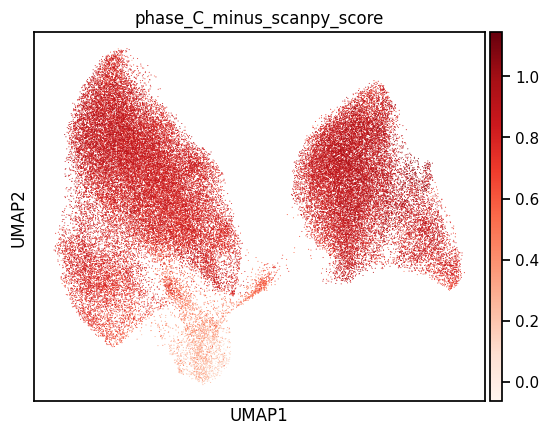

In [112]:
# Check if they are ooligos contamiantion
df_Cminus = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all/phase_c_minus_genes.csv")
df_Cminus
dict_oligo={"phase_C_minus_scanpy": df_Cminus["Gene"].tolist()}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_msn, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap")

Assure that adata.var.index has same gene name of makers...


  0%|          | 0/1 [00:00<?, ?it/s]

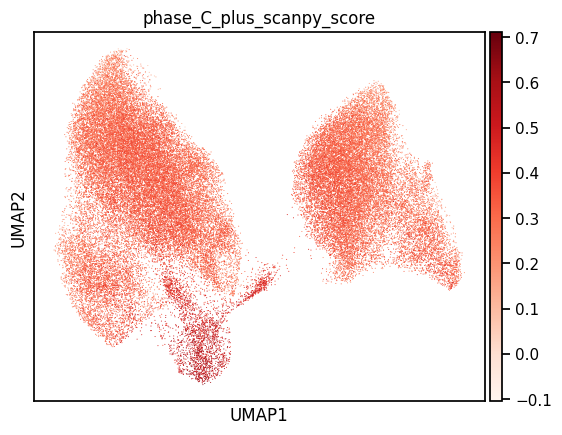

In [113]:
# Check if they are ooligos contamiantion
df_Cplus = pd.read_csv("/home/gdallagl/myworkdir/XDP/utils/handsaker_et_all/phase_c_plus_genes.csv")
df_Cplus
dict_oligo={"phase_C_plus_scanpy": df_Cplus["Gene"].tolist()}
col_oligo_score = preprocessing.calculate_and_plot_markers(adata_msn, dict_oligo, gene_col="gene_symbol", ncol=3, layer="log1p_norm", color_map="Reds", umap_name=f"umap")